<a href="https://colab.research.google.com/github/Tashfi12/Deep-Learning-Architecture-for-ECG-Heartbeat-Classification/blob/main/Final_ECG_Signal_Heartbeat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Install Required Packages**

In [ ]:
!pip install -q kagglehub

**Import Libraries**

In [ ]:
import os
import gc
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report,confusion_matrix, accuracy_score,
                              precision_score,recall_score, f1_score)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Reproducibility**

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


**Download Kaggle Dataset**

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download("shayanfazeli/heartbeat")

print("Dataset path:")
print(dataset_path)

print("\nFiles:")
print(os.listdir(dataset_path))

Using Colab cache for faster access to the 'heartbeat' dataset.
Dataset path:
/kaggle/input/heartbeat

Files:
['ptbdb_abnormal.csv', 'ptbdb_normal.csv', 'mitbih_test.csv', 'mitbih_train.csv']


**Load MIT-BIH Dataset**

In [ ]:
train_file = os.path.join(dataset_path, "mitbih_train.csv")
test_file = os.path.join(dataset_path, "mitbih_test.csv")
train_df = pd.read_csv(train_file, header=None)
test_df = pd.read_csv(test_file, header=None)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (87554, 188)
Testing shape: (21892, 188)


**Basic Data Inspection**

In [ ]:
print("First 5 rows:")
display(train_df.head())

print("\nData types:")
print(train_df.dtypes.value_counts())

print("\nMissing values:")
print("Train:", train_df.isnull().sum().sum())
print("Test :", test_df.isnull().sum().sum())

First 5 rows:


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Data types:
float64    188
Name: count, dtype: int64

Missing values:
Train: 0
Test : 0


**Separate Features and Labels**

In [ ]:
X_train_full = train_df.iloc[:, :-1].values.astype("float32")
y_train_full = train_df.iloc[:, -1].values.astype("int32")

X_test = test_df.iloc[:, :-1].values.astype("float32")
y_test = test_df.iloc[:, -1].values.astype("int32")

print("X_train_full:", X_train_full.shape)
print("y_train_full:", y_train_full.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train_full: (87554, 187)
y_train_full: (87554,)
X_test: (21892, 187)
y_test: (21892,)


**Define Classes**

In [ ]:
class_names = { 0: "Normal (N)",
                1: "Supraventricular (S)",
                2: "Ventricular (V)",
                3: "Fusion (F)",
                4: "Unknown (Q)" }

num_classes = 5

print("Classes:")

for i in range(num_classes):
    print(i, "=", class_names[i])

Classes:
0 = Normal (N)
1 = Supraventricular (S)
2 = Ventricular (V)
3 = Fusion (F)
4 = Unknown (Q)


**Class Distribution**

In [ ]:
classes, counts = np.unique(y_train_full, return_counts=True)

distribution_df = pd.DataFrame({
    "Class": classes,
    "Name": [class_names[c] for c in classes],
    "Count": counts,
    "Percentage": counts / len(y_train_full) * 100
})

display(distribution_df)

,Class,Name,Count,Percentage
0,0,Normal (N),72471,82.772917
1,1,Supraventricular (S),2223,2.539005
2,2,Ventricular (V),5788,6.610777
3,3,Fusion (F),641,0.732120
4,4,Unknown (Q),6431,7.345181


**Visualize Class Distribution**

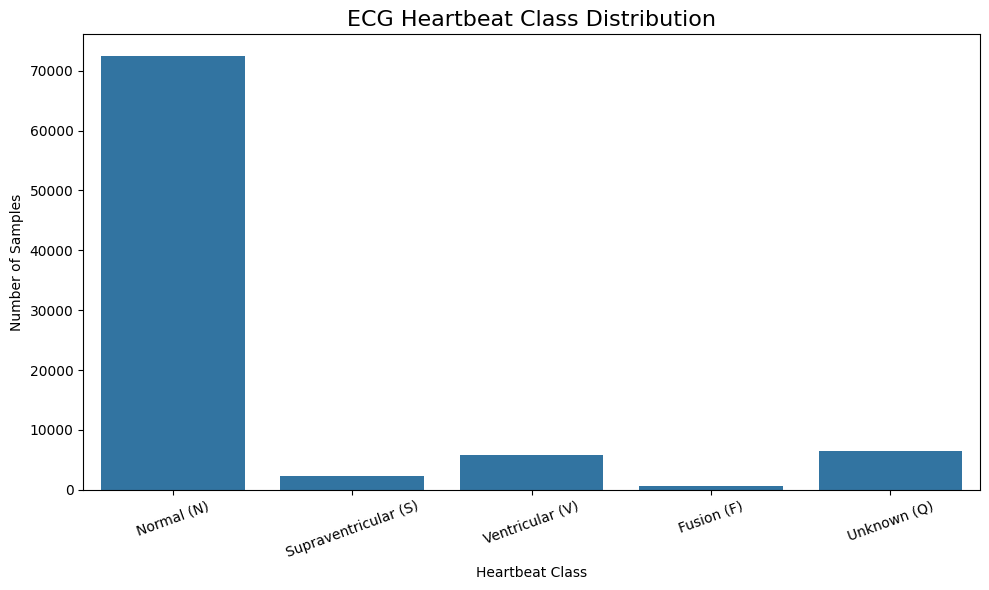

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(data=distribution_df, x="Name", y="Count")
plt.title("ECG Heartbeat Class Distribution", fontsize=16)
plt.xlabel("Heartbeat Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Visualize ECG Signals**

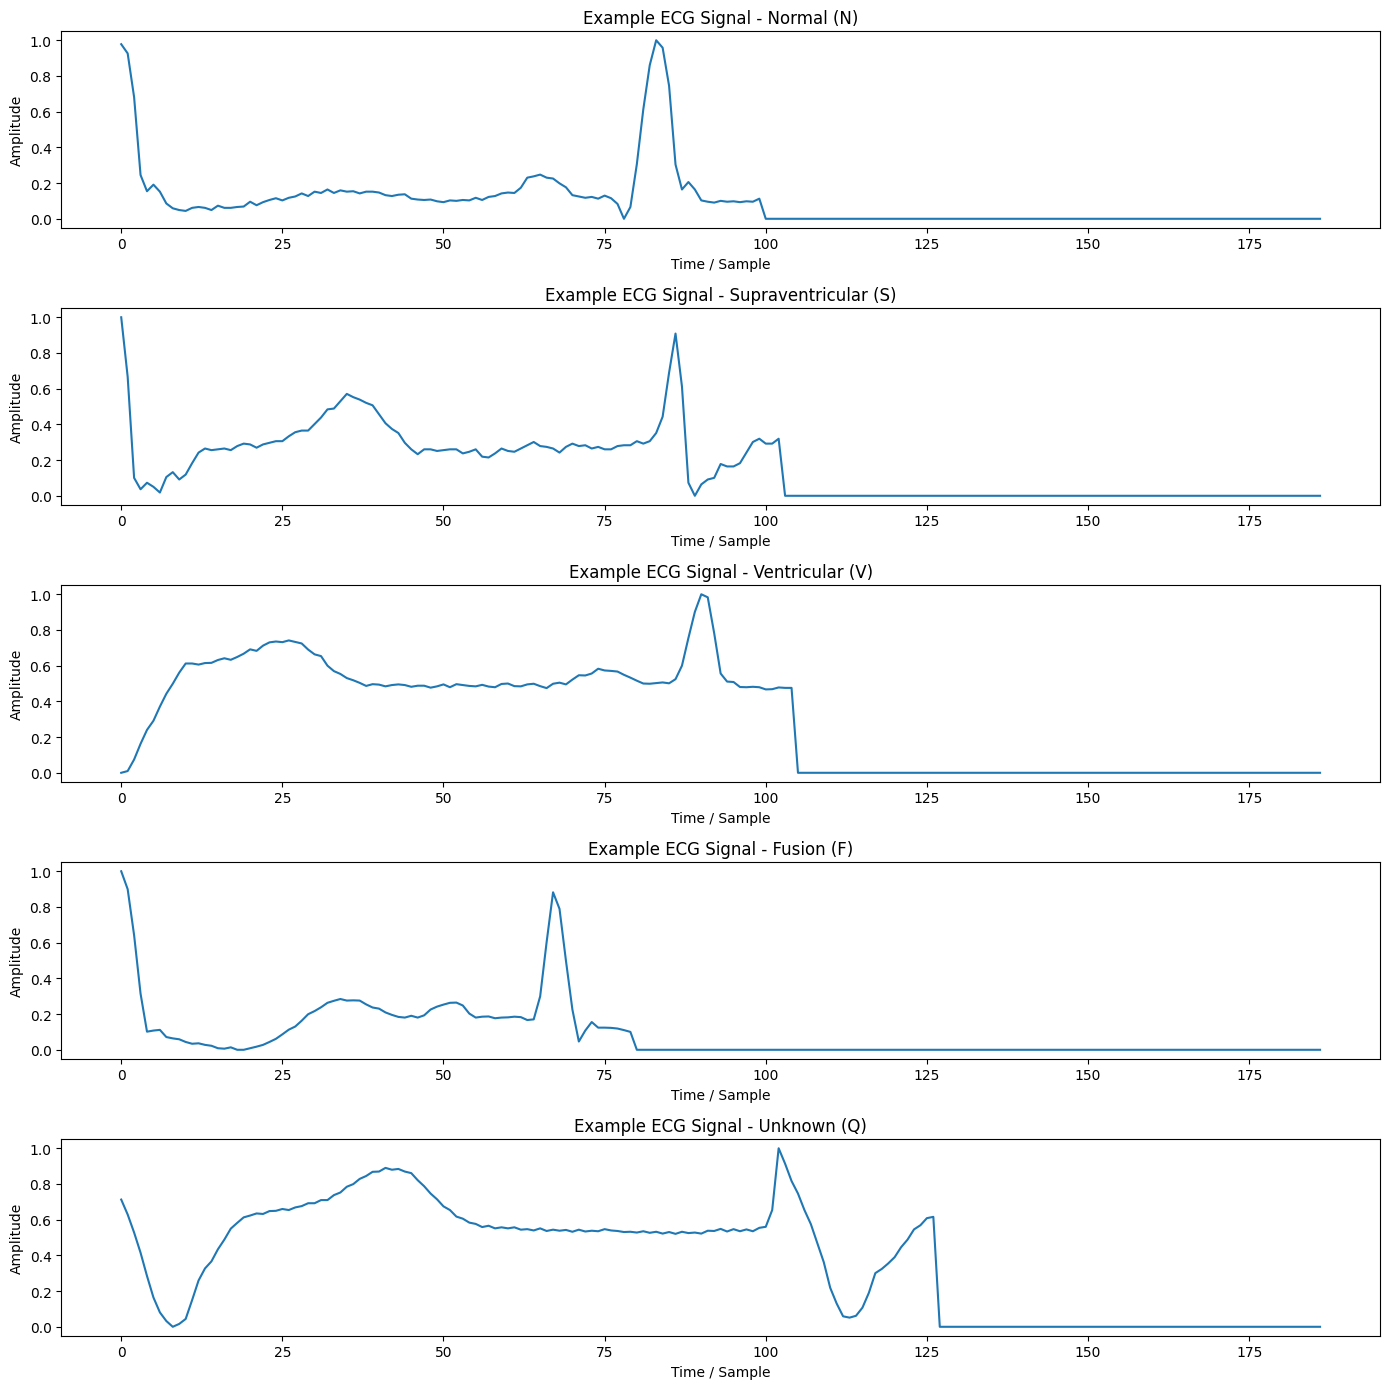

In [ ]:
fig, axes = plt.subplots(num_classes,1,figsize=(14, 14))

for class_id in range(num_classes):indices = np.where(y_train_full == class_id)[0]

    sample_index = indices[0]

    axes[class_id].plot(X_train_full[sample_index])

    axes[class_id].set_title(f"Example ECG Signal - {class_names[class_id]}")

    axes[class_id].set_xlabel("Time / Sample")
    axes[class_id].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

**Check Data Range**

In [ ]:
print("Minimum value:", X_train_full.min())
print("Maximum value:", X_train_full.max())

print("Mean:", X_train_full.mean())
print("Standard deviation:", X_train_full.std())

Minimum value: 0.0
Maximum value: 1.0
Mean: 0.17428276
Standard deviation: 0.22632729


**Stratified Train/Validation Split**

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X_train_full,y_train_full,test_size=0.20,
                                                   random_state=SEED, stratify=y_train_full)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (70043, 187)
Validation: (17511, 187)
Testing: (21892, 187)


**Reshape ECG Data for 1D Deep Learning**

In [ ]:
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (70043, 187, 1)
Validation shape: (17511, 187, 1)
Testing shape: (21892, 187, 1)


**Moderate Class Weighting**

In [ ]:
original_class_weights = compute_class_weight(class_weight="balanced",
                                                classes=np.unique(y_train),
                                                y=y_train)

class_weights = {int(cls): float(np.sqrt(weight))
                  for cls, weight in zip(
                    np.unique(y_train),
                    original_class_weights)
                }

print("Moderated class weights:")

for cls, weight in class_weights.items():
    print(f"{cls} - {class_names[cls]}: {weight:.4f}")

Moderated class weights:
0 - Normal (N): 0.4916
1 - Supraventricular (S): 2.8069
2 - Ventricular (V): 1.7394
3 - Fusion (F): 5.2256
4 - Unknown (Q): 1.6501


**TensorFlow Data Pipelines**

In [ ]:
BATCH_SIZE = 256
train_ds = (tf.data.Datasetfrom_tensor_slices((X_train, y_train))shuffle(20000,seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = (tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
test_ds = (tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

print("TensorFlow datasets created.")

TensorFlow datasets created.


**Common Training Callbacks**

In [ ]:
def create_callbacks(model_name):
    checkpoint_path = (f"/content/best_{model_name}.keras")
    callbacks = [
                  tf.keras.callbacks.ModelCheckpoint(checkpoint_path,monitor="val_loss",save_best_only=True,verbose=1),
                  tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=6,restore_best_weights=True,verbose=1),
                  tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=2,min_lr=1e-6,verbose=1)
    ]

    return callbacks

# **1D CNN Model**

In [ ]:
def build_cnn(filters1=64,filters2=128,filters3=256,dropout=0.30,learning_rate=0.001):

    model = models.Sequential(name="Baseline_1D_CNN")
    model.add(layers.Input(shape=(187, 1)))

    # Block 1
    model.add(layers.Conv1D(filters1,kernel_size=7,padding="same",activation="relu"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling1D(pool_size=2))
    model.add(layers.Dropout(dropout))

    # Block 2
    model.add(layers.Conv1D(filters2,kernel_size=5,padding="same",activation="relu"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling1D(pool_size=2))
    model.add(layers.Dropout(dropout))

    # Block 3
    model.add(layers.Conv1D(filters3,kernel_size=3,padding="same",activation="relu"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling1D(pool_size=2))
    model.add(layers.Dropout(dropout))

    # Block 4
    model.add(layers.Conv1D(filters3,kernel_size=3,padding="same",activation="relu"))
    model.add(layers.BatchNormalization())

    # Global feature extraction
    model.add(layers.GlobalAveragePooling1D())

    # Dense classifier
    model.add(layers.Dense(128,activation="relu"))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.40))

    model.add(layers.Dense(num_classes,activation="softmax"))

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    return model

cnn = build_cnn()

cnn.summary()

Model: "Baseline_1D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 187, 64)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 187, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 93, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 93, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 93, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 93, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 46, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 46, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 46, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 46, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 23, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 23, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 23, 256)        │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 23, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 373,893 (1.43 MB)

 Trainable params: 372,229 (1.42 MB)

 Non-trainable params: 1,664 (6.50 KB)

**Visualize CNN Architecture**

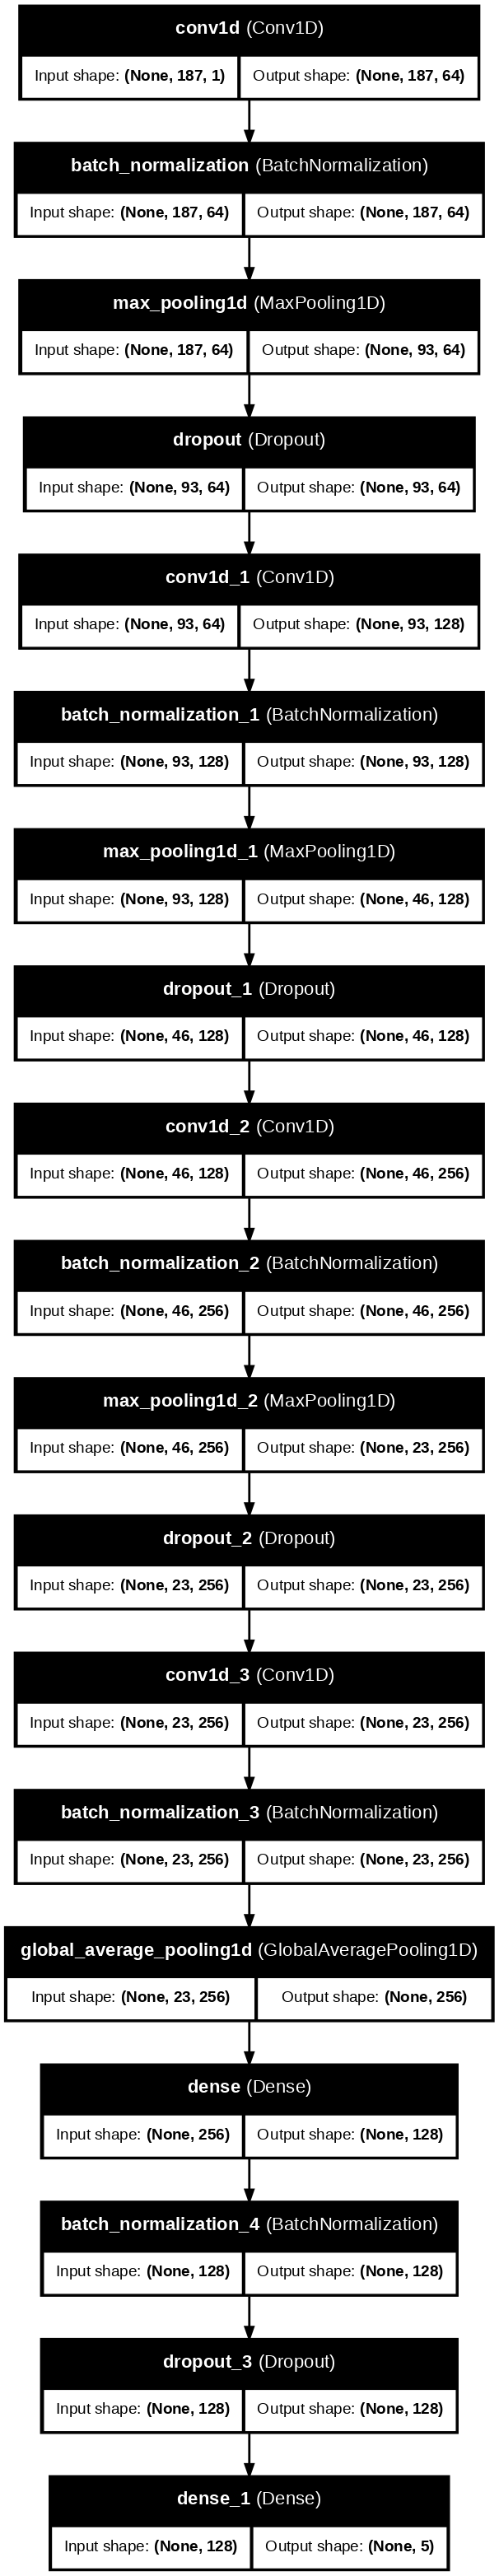

In [ ]:
from tensorflow.keras.utils import plot_model

plot_model(
    cnn,
    to_file="/content/cnn_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    dpi=100
)

**Train CNN**

In [ ]:
cnn_callbacks = create_callbacks("cnn")

history_cnn = cnn.fit(train_ds,validation_data=val_ds,epochs=30, class_weight=class_weights,
                        callbacks=cnn_callbacks,verbose=1)

Epoch 1/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5866 - loss: 0.9167
Epoch 1: val_loss improved from None to 9.88983, saving model to /content/best_cnn.keras

Epoch 1: finished saving model to /content/best_cnn.keras
274/274 ━━━━━━━━━━━━━━━━━━━━ 29s 49ms/step - accuracy: 0.7593 - loss: 0.6085 - val_accuracy: 0.0661 - val_loss: 9.8898 - learning_rate: 0.0010
Epoch 2/30
273/274 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9190 - loss: 0.3118
Epoch 2: val_loss improved from 9.88983 to 1.64149, saving model to /content/best_cnn.keras

Epoch 2: finished saving model to /content/best_cnn.keras
274/274 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9269 - loss: 0.2877 - val_accuracy: 0.1685 - val_loss: 1.6415 - learning_rate: 0.0010
Epoch 3/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9408 - loss: 0.2393
Epoch 3: val_loss improved from 1.64149 to 0.50210, saving model to /content/best_cnn.keras

Epoch 3: finished saving model to /content/best_cnn.keras
274/

**CNN Training Curves**

In [ ]:
def plot_training_history(history,model_name):

    plt.figure(figsize=(12, 5))
    plt.plot(history.history["accuracy"],label="Training Accuracy")
    plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
    plt.title(f"{model_name} - Accuracy")

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 5))
    plt.plot(history.history["loss"],label="Training Loss")
    plt.plot(history.history["val_loss"],label="Validation Loss")
    plt.title(f"{model_name} - Loss")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

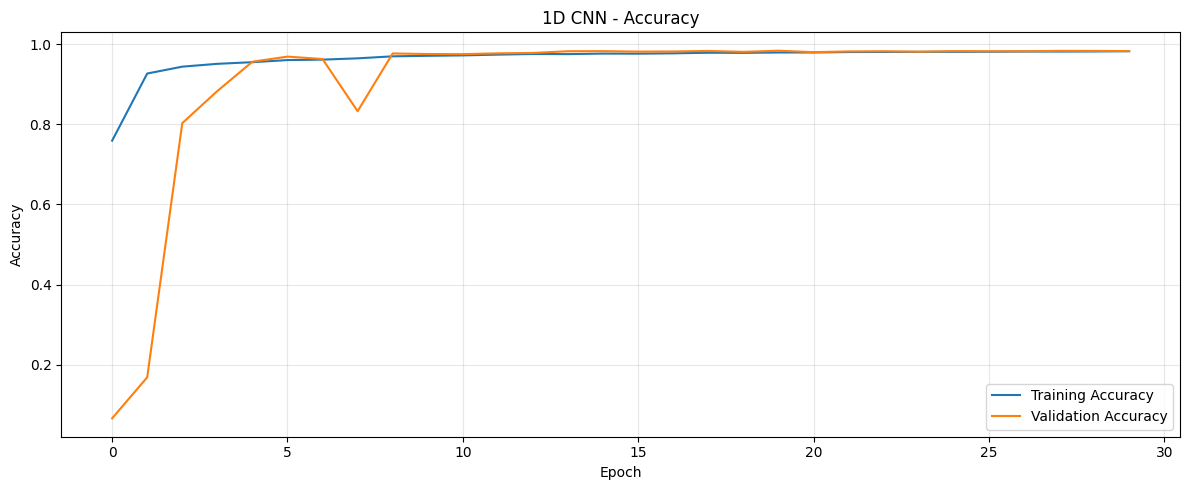

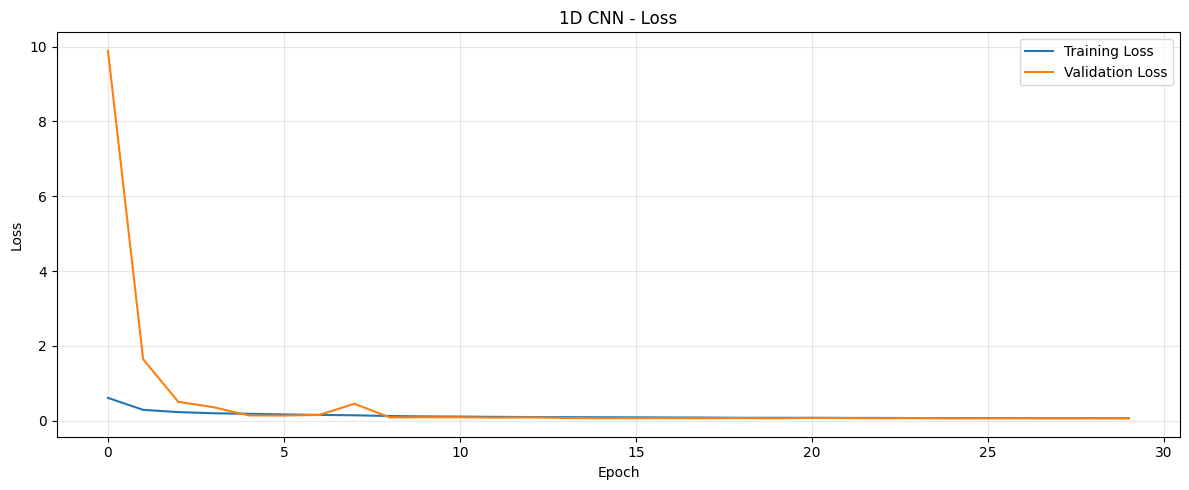

In [ ]:
plot_training_history(history_cnn,"1D CNN")

**CNN Evaluation**

In [ ]:
cnn_test_loss, cnn_test_accuracy = cnn.evaluate(test_ds,verbose=1)

print(f"1D CNN Test Accuracy: "f"{cnn_test_accuracy * 100:.2f}%")

86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9830 - loss: 0.0616
1D CNN Test Accuracy: 98.30%


**CNN Predictions**

In [ ]:
cnn_probabilities = cnn.predict(test_ds,verbose=1)
cnn_predictions = np.argmax(cnn_probabilities,axis=1)

86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


**CNN Classification Report**

In [ ]:
cnn_report = classification_report(y_test,cnn_predictions,
                                    target_names=[class_names[i]
                                                    for i in range(num_classes)],digits=4,zero_division=0)

print(cnn_report)

                      precision    recall  f1-score   support

          Normal (N)     0.9944    0.9879    0.9911     18118
Supraventricular (S)     0.7751    0.8741    0.8216       556
     Ventricular (V)     0.9667    0.9620    0.9643      1448
          Fusion (F)     0.6938    0.8951    0.7817       162
         Unknown (Q)     0.9882    0.9932    0.9907      1608

            accuracy                         0.9830     21892
           macro avg     0.8836    0.9424    0.9099     21892
        weighted avg     0.9843    0.9830    0.9835     21892



**CNN Confusion Matrix**

In [ ]:
def plot_confusion_matrix(y_true,y_pred,model_name):

    cm = confusion_matrix(y_true,y_pred)
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
                  xticklabels=[
                        class_names[i]
                        for i in range(num_classes)],
                  yticklabels=[
                        class_names[i]
                        for i in range(num_classes)])
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel()"Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

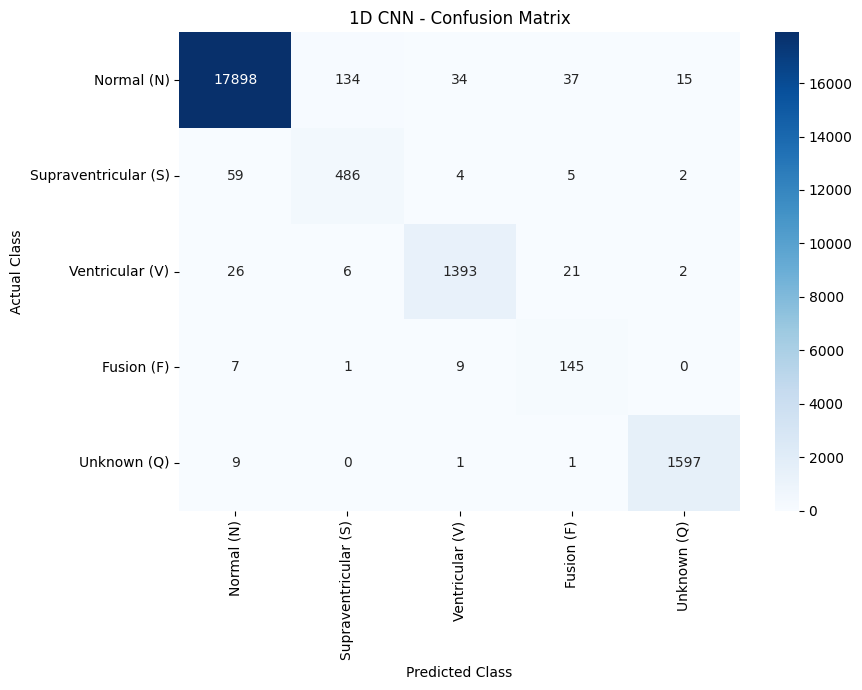

In [ ]:
plot_confusion_matrix(
    y_test,
    cnn_predictions,
    "1D CNN"
)

# **CNN + BiLSTM**

In [ ]:
def build_cnn_bilstm(filters=64,lstm_units=64,dropout=0.30,learning_rate=0.001):

    inputs = layers.Input(shape=(187, 1))

    # ==========================
    # CNN FEATURE EXTRACTION
    # ==========================
    x = layers.Conv1D(filters=filters,kernel_size=7,padding="same",activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Conv1D(filters=filters * 2,kernel_size=5,padding="same",activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Conv1D(filters=filters * 2,kernel_size=3,padding="same",activation="relu")(x)
    x = layers.BatchNormalization()(x)

    # ==========================
    # TEMPORAL LEARNING
    # ==========================
    x = layers.Bidirectional(layers.LSTM(lstm_units,return_sequences=True))(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Bidirectional(layers.LSTM(lstm_units // 2,return_sequences=False))(x)
    x = layers.Dropout(0.40)(x)

    # ==========================
    # CLASSIFIER
    # ==========================
    x = layers.Dense(128,activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(num_classes,activation="softmax")(x)
    model = models.Model(inputs,outputs,name="CNN_BiLSTM")

    model.compile(optimizer=tf.keras.optimizers.Adam(
                   learning_rate=learning_rate),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

    return model

cnn_bilstm = build_cnn_bilstm()
cnn_bilstm.summary()

Model: "CNN_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 187, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 187, 64)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 187, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 93, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 93, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 93, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 93, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 46, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 46, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 46, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 46, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 46, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 46, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,669 (944.02 KB)

 Trainable params: 240,773 (940.52 KB)

 Non-trainable params: 896 (3.50 KB)

**CNN-BiLSTM Architecture Visualization**

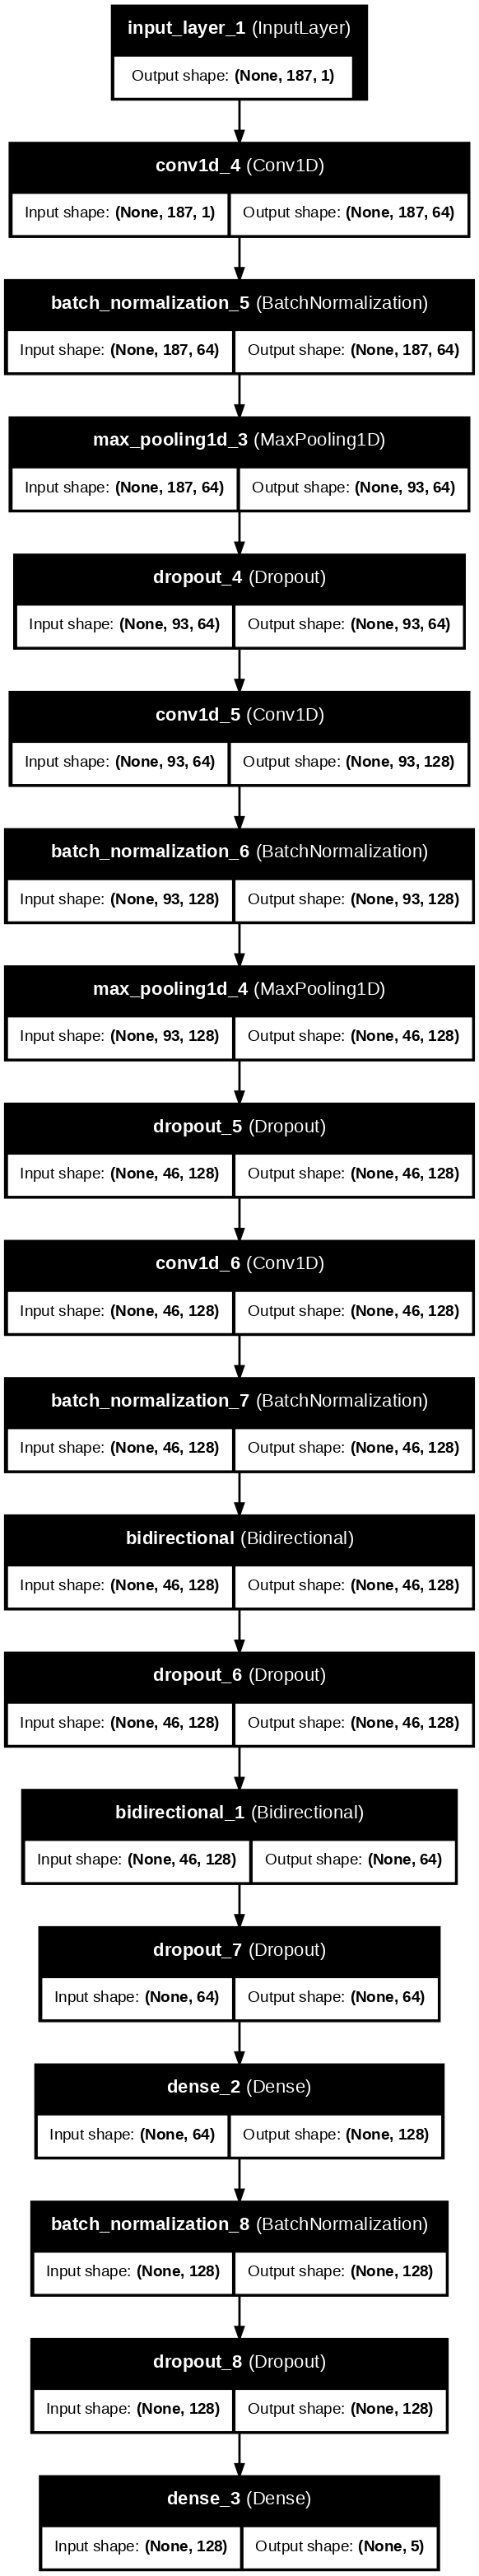

In [ ]:
from IPython.display import Image

plot_model(cnn_bilstm,to_file="/content/cnn_bilstm_architecture.png",
            show_shapes=True,show_layer_names=True,dpi=100)

display(Image(filename="/content/cnn_bilstm_architecture.png"))

**Train CNN-BiLSTM**

In [ ]:
cnn_bilstm_callbacks = create_callbacks("cnn_bilstm")

history_cnn_bilstm = cnn_bilstm.fit(train_ds,validation_data=val_ds,epochs=30,
                                     class_weight=class_weights,callbacks=cnn_bilstm_callbacks,verbose=1)

Epoch 1/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5868 - loss: 0.9800
Epoch 1: val_loss improved from None to 1.08974, saving model to /content/best_cnn_bilstm.keras

Epoch 1: finished saving model to /content/best_cnn_bilstm.keras
274/274 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - accuracy: 0.7654 - loss: 0.6629 - val_accuracy: 0.8059 - val_loss: 1.0897 - learning_rate: 0.0010
Epoch 2/30
273/274 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9127 - loss: 0.3593
Epoch 2: val_loss improved from 1.08974 to 0.99399, saving model to /content/best_cnn_bilstm.keras

Epoch 2: finished saving model to /content/best_cnn_bilstm.keras
274/274 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.9242 - loss: 0.3267 - val_accuracy: 0.6807 - val_loss: 0.9940 - learning_rate: 0.0010
Epoch 3/30
273/274 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9393 - loss: 0.2682
Epoch 3: val_loss improved from 0.99399 to 0.17322, saving model to /content/best_cnn_bilstm.keras

Epoch 3: finished saving m

**CNN-BiLSTM Curves**

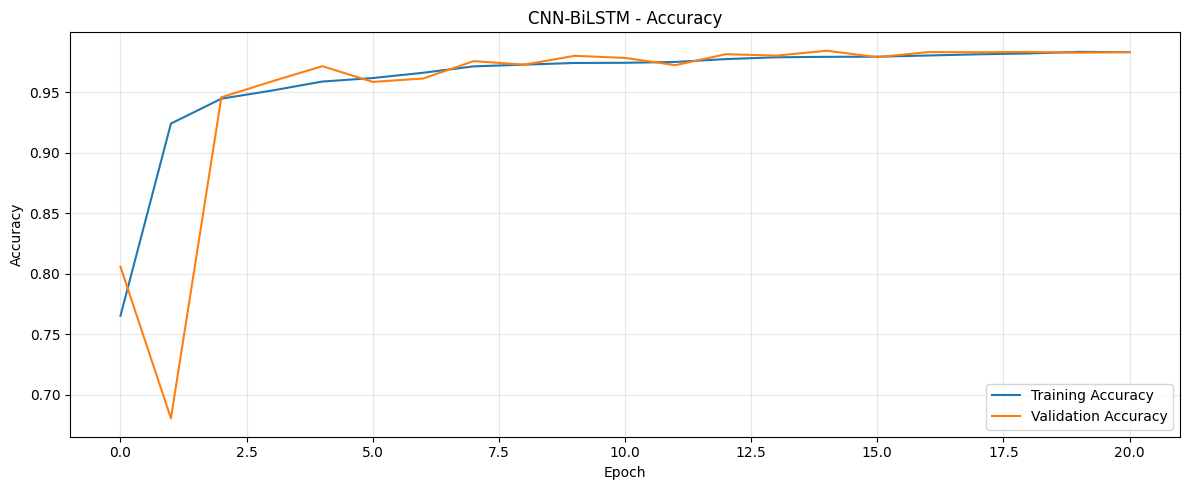

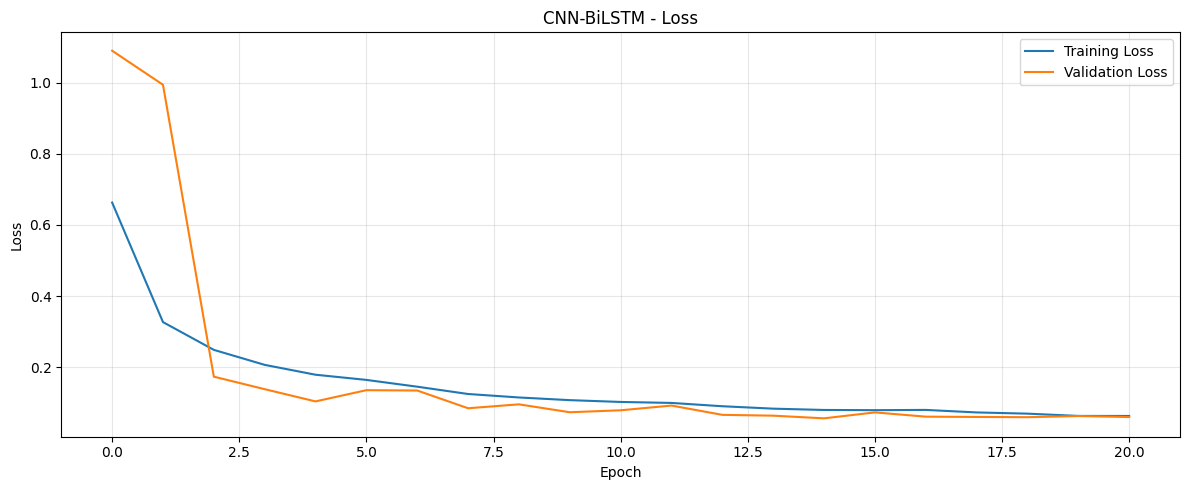

In [ ]:
plot_training_history(history_cnn_bilstm,"CNN-BiLSTM")

**CNN-BiLSTM Evaluation**

In [ ]:
bilstm_test_loss, bilstm_test_accuracy = (cnn_bilstm.evaluate(test_ds,verbose=1))

print(f"CNN-BiLSTM Test Accuracy: " f"{bilstm_test_accuracy * 100:.2f}%")

86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9840 - loss: 0.0570
CNN-BiLSTM Test Accuracy: 98.40%


**CNN-BiLSTM Predictions**

In [ ]:
bilstm_probabilities = cnn_bilstm.predict(test_ds,verbose=1)
bilstm_predictions = np.argmax(bilstm_probabilities,axis=1)

86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step


**CNN-BiLSTM Report**

In [ ]:
print(classification_report(y_test,bilstm_predictions,
                             target_names=[class_names[i]
                                            for i in range(num_classes)],digits=4,zero_division=0))

                      precision    recall  f1-score   support

          Normal (N)     0.9917    0.9921    0.9919     18118
Supraventricular (S)     0.8032    0.8219    0.8124       556
     Ventricular (V)     0.9711    0.9510    0.9609      1448
          Fusion (F)     0.8070    0.8519    0.8288       162
         Unknown (Q)     0.9913    0.9925    0.9919      1608

            accuracy                         0.9840     21892
           macro avg     0.9129    0.9219    0.9172     21892
        weighted avg     0.9842    0.9840    0.9841     21892



**CNN-BiLSTM Confusion Matrix**

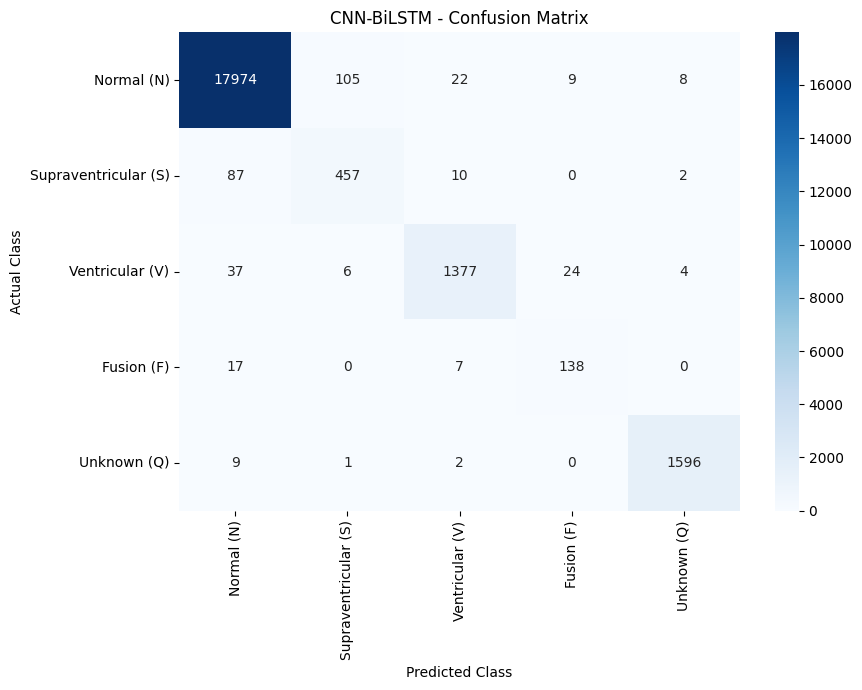

In [ ]:
plot_confusion_matrix(y_test,bilstm_predictions,"CNN-BiLSTM")

# **ResNet1D**

In [ ]:
def residual_block(x,filters,kernel_size=5,stride=1,dropout=0.20):

    shortcut = x

    # First convolution
    x = layers.Conv1D(filters=filters,kernel_size=kernel_size,strides=stride,padding="same",use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(dropout)(x)

    # Second convolution
    x = layers.Conv1D(filters=filters,kernel_size=kernel_size,padding="same",use_bias=False)(x)
    x = layers.BatchNormalization()(x)

    # Match shortcut dimensions
    if (shortcut.shape[-1] != filters
        or stride != 1):

        shortcut = layers.Conv1D(filters=filters,kernel_size=1,strides=stride,padding="same",use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    # Residual addition
    x = layers.Add()([x,shortcut])x = layers.Activation("relu")(x)

    return x

In [ ]:
def build_resnet1d(dropout=0.20,learning_rate=0.001):

    inputs = layers.Input(shape=(187, 1))

    # Initial feature extraction
    x = layers.Conv1D(64,kernel_size=7,padding="same",use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(pool_size=2)(x)

    # ==========================
    # RESIDUAL STAGE 1
    # ==========================
    x = residual_block(x,filters=64,kernel_size=5,dropout=dropout)
    x = residual_block(x,filters=64,kernel_size=5,dropout=dropout)

    # ==========================
    # RESIDUAL STAGE 2
    # ==========================
    x = residual_block(x,filters=128,kernel_size=5,stride=2,dropout=dropout)
    x = residual_block(x,filters=128,kernel_size=5,dropout=dropout)

    # ==========================
    # RESIDUAL STAGE 3
    # ==========================
    x = residual_block(x,filters=256,kernel_size=3,stride=2,dropout=dropout)
    x = residual_block(x,filters=256,kernel_size=3,dropout=dropout)

    # ==========================
    # CLASSIFIER
    # ==========================
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128,activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(num_classes,activation="softmax")(x)

    model = models.Model(inputs,outputs,name="ResNet1D")
    model.compile(optimizer=tf.keras.optimizers.Adam(
                   learning_rate=learning_rate),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return model

resnet1d = build_resnet1d()
resnet1d.summary()

Model: "ResNet1D"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 187, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 187, 64)   │        448 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 187, 64)   │        256 │ conv1d_7[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 187, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 93, 64)    │          0 │ activation[0][0]  │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 93, 64)    │     20,480 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 64)    │        256 │ conv1d_8[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 93, 64)    │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 93, 64)    │          0 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 93, 64)    │     20,480 │ dropout_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 64)    │        256 │ conv1d_9[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 93, 64)    │          0 │ batch_normalizat… │
│                     │                   │            │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 93, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 93, 64)    │     20,480 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 64)    │        256 │ conv1d_10[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 93, 64)    │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 93, 64)    │          0 │ activation_3[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 93, 64)    │     20,480 │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 64)    │        256 │ conv1d_11[0][0] 

 Total params: 1,141,189 (4.35 MB)

 Trainable params: 1,136,453 (4.34 MB)

 Non-trainable params: 4,736 (18.50 KB)

**ResNet1D Architecture**

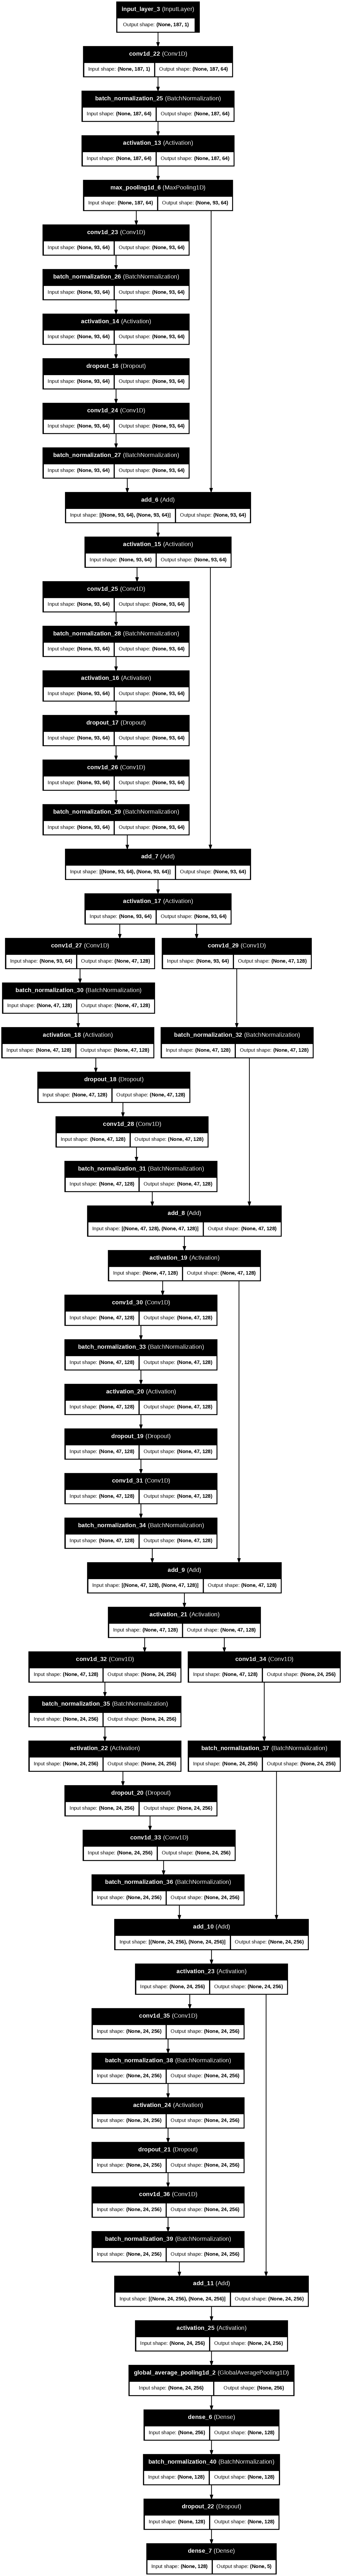

In [ ]:
plot_model(resnet1d,to_file="/content/resnet1d_architecture.png",
            show_shapes=True,show_layer_names=True,dpi=100)

display(Image(filename="/content/resnet1d_architecture.png"))

**Train ResNet1D**

In [ ]:
resnet_callbacks = create_callbacks("resnet1d")
history_resnet = resnet1d.fit(train_ds,validation_data=val_ds,epochs=30,
                                class_weight=class_weights,callbacks=resnet_callbacks,verbose=1)

Epoch 1/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.6941 - loss: 0.7207
Epoch 1: val_loss improved from None to 9.16147, saving model to /content/best_resnet1d.keras

Epoch 1: finished saving model to /content/best_resnet1d.keras
274/274 ━━━━━━━━━━━━━━━━━━━━ 48s 91ms/step - accuracy: 0.8492 - loss: 0.4446 - val_accuracy: 0.0702 - val_loss: 9.1615 - learning_rate: 0.0010
Epoch 2/30
273/274 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9449 - loss: 0.2284
Epoch 2: val_loss improved from 9.16147 to 1.88448, saving model to /content/best_resnet1d.keras

Epoch 2: finished saving model to /content/best_resnet1d.keras
274/274 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.9496 - loss: 0.2141 - val_accuracy: 0.2488 - val_loss: 1.8845 - learning_rate: 0.0010
Epoch 3/30
273/274 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9539 - loss: 0.1874
Epoch 3: val_loss improved from 1.88448 to 0.29590, saving model to /content/best_resnet1d.keras

Epoch 3: finished saving model to /c

**ResNet1D Curves**

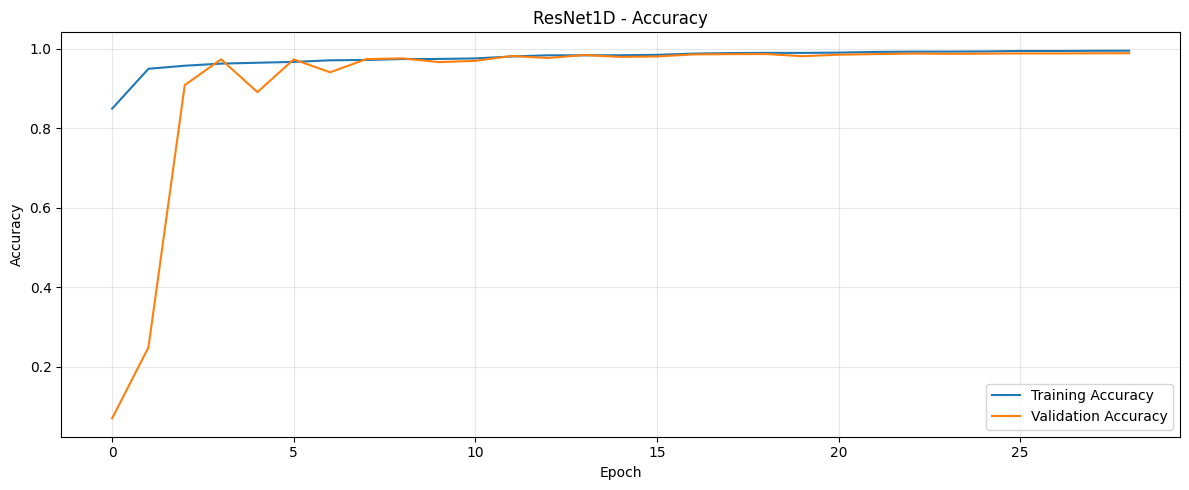

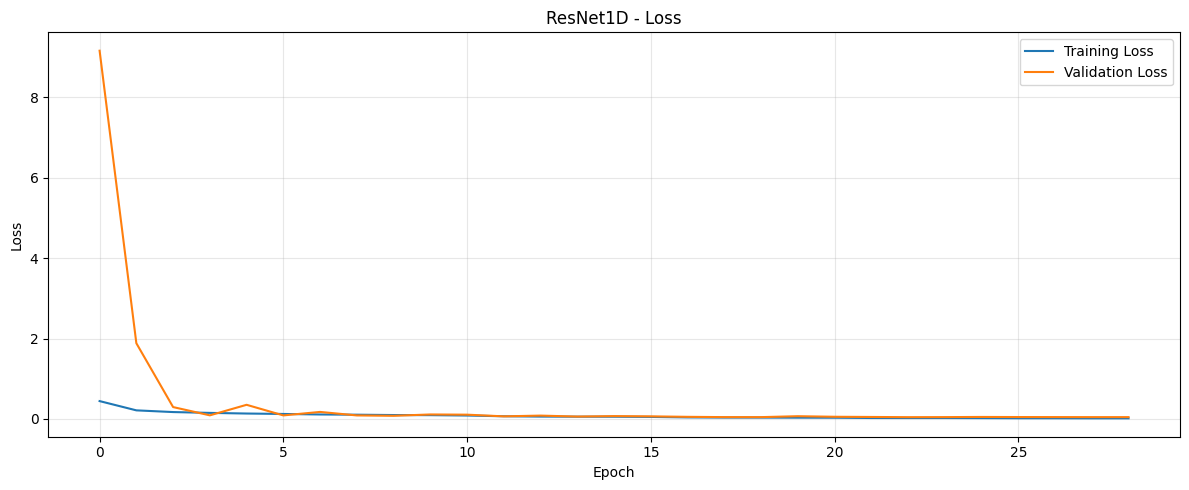

In [ ]:
plot_training_history(history_resnet,"ResNet1D")

**ResNet1D Evaluation**

In [ ]:
resnet_test_loss, resnet_test_accuracy = (resnet1d.evaluate(test_ds,verbose=1))

print(f"ResNet1D Test Accuracy: "f"{resnet_test_accuracy * 100:.2f}%")

86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9872 - loss: 0.0514
ResNet1D Test Accuracy: 98.72%


**ResNet1D Predictions**

In [ ]:
resnet_probabilities = resnet1d.predict(test_ds,verbose=1)
resnet_predictions = np.argmax(resnet_probabilities,axis=1)

86/86 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step


**ResNet1D Classification Report**

In [ ]:
print(classification_report(y_test,resnet_predictions,target_names=[class_names[i]
                                                                      for i in range(num_classes)],digits=4,zero_division=0))

                      precision    recall  f1-score   support

          Normal (N)     0.9932    0.9942    0.9937     18118
Supraventricular (S)     0.8767    0.8309    0.8532       556
     Ventricular (V)     0.9756    0.9662    0.9709      1448
          Fusion (F)     0.7688    0.8827    0.8218       162
         Unknown (Q)     0.9913    0.9919    0.9916      1608

            accuracy                         0.9872     21892
           macro avg     0.9211    0.9332    0.9262     21892
        weighted avg     0.9873    0.9872    0.9872     21892



**ResNet1D Confusion Matrix**

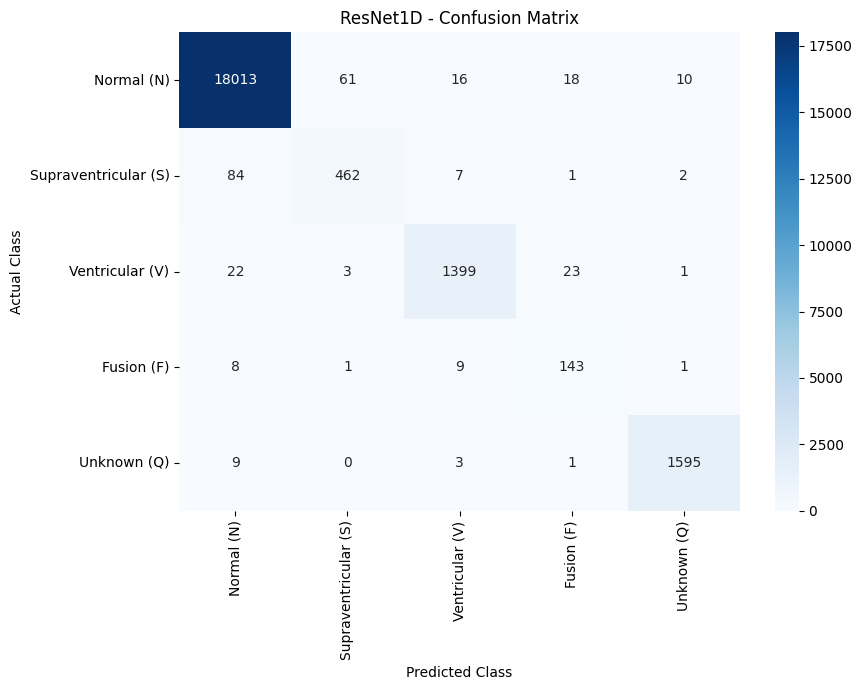

In [ ]:
plot_confusion_matrix(y_test,resnet_predictions,"ResNet1D")

**Model Comparison Function**

In [ ]:
def calculate_metrics(y_true,y_pred,model_name):

    return {"Model": model_name,
            "Accuracy": accuracy_score(y_true,y_pred),
            "Macro Precision": precision_score(y_true,y_pred,average="macro",zero_division=0),
            "Macro Recall": recall_score(y_true,y_pred,average="macro",zero_division=0),
            "Macro F1": f1_score(y_true,y_pred,average="macro",zero_division=0),
            "Weighted F1": f1_score(y_true,y_pred,average="weighted",zero_division=0)
    }

**Final Comparison Table**

In [ ]:
results = pd.DataFrame([
    calculate_metrics(y_test,cnn_predictions,"1D CNN"),
    calculate_metrics(y_test,bilstm_predictions,"CNN-BiLSTM"),
    calculate_metrics(y_test,resnet_predictions,"ResNet1D")])

display(results.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,1D CNN,0.9830,0.8836,0.9424,0.9099,0.9835
1,CNN-BiLSTM,0.9840,0.9129,0.9219,0.9172,0.9841
2,ResNet1D,0.9872,0.9211,0.9332,0.9262,0.9872


**Percentage Results**

In [ ]:
results_percent = results.copy()
metric_columns = ["Accuracy","Macro Precision","Macro Recall","Macro F1","Weighted F1"]
for column in metric_columns:
    results_percent[column] *= 100

display(results_percent.round(2))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,1D CNN,98.30,88.36,94.24,90.99,98.35
1,CNN-BiLSTM,98.40,91.29,92.19,91.72,98.41
2,ResNet1D,98.72,92.11,93.32,92.62,98.72


**Determine Best Model**

In [ ]:
best_model_row = results.loc[results["Macro F1"].idxmax()]

print("Best model based on Macro F1:")
print(best_model_row["Model"])
print(f"\nMacro F1: "f"{best_model_row['Macro F1'] * 100:.2f}%")

print(f"Accuracy: "f"{best_model_row['Accuracy'] * 100:.2f}%")

Best model based on Macro F1:
ResNet1D

Macro F1: 92.62%
Accuracy: 98.72%


**Per-Class Performance**

In [ ]:
def class_metrics(y_true,y_pred,model_name):
    report = classification_report(y_true,y_pred,output_dict=True,zero_division=0)

    rows = []

    for class_id in range(num_classes):
        class_result = report[
            str(class_id)]

        rows.append({
            "Model": model_name,
            "Class": class_names[class_id],
            "Precision":class_result["precision"],
            "Recall":class_result["recall"],
            "F1":class_result["f1-score"],
            "Support":class_result["support"]})

    return pd.DataFrame(rows)

In [ ]:
per_class_results = pd.concat([
    class_metrics(y_test,cnn_predictions,"1D CNN"),
    class_metrics(y_test,bilstm_predictions,"CNN-BiLSTM"),
    class_metrics(y_test,resnet_predictions,"ResNet1D")], ignore_index=True)
display(per_class_results.round(4))

,Model,Class,Precision,Recall,F1,Support
0,1D CNN,Normal (N),0.9944,0.9879,0.9911,18118.0
1,1D CNN,Supraventricular (S),0.7751,0.8741,0.8216,556.0
2,1D CNN,Ventricular (V),0.9667,0.9620,0.9643,1448.0
3,1D CNN,Fusion (F),0.6938,0.8951,0.7817,162.0
4,1D CNN,Unknown (Q),0.9882,0.9932,0.9907,1608.0
5,CNN-BiLSTM,Normal (N),0.9917,0.9921,0.9919,18118.0
6,CNN-BiLSTM,Supraventricular (S),0.8032,0.8219,0.8124,556.0
7,CNN-BiLSTM,Ventricular (V),0.9711,0.9510,0.9609,1448.0
8,CNN-BiLSTM,Fusion (F),0.8070,0.8519,0.8288,162.0
9,CNN-BiLSTM,Unknown (Q),0.9913,0.9925,0.9919,1608.0


**Per-Class F1 Visualization**

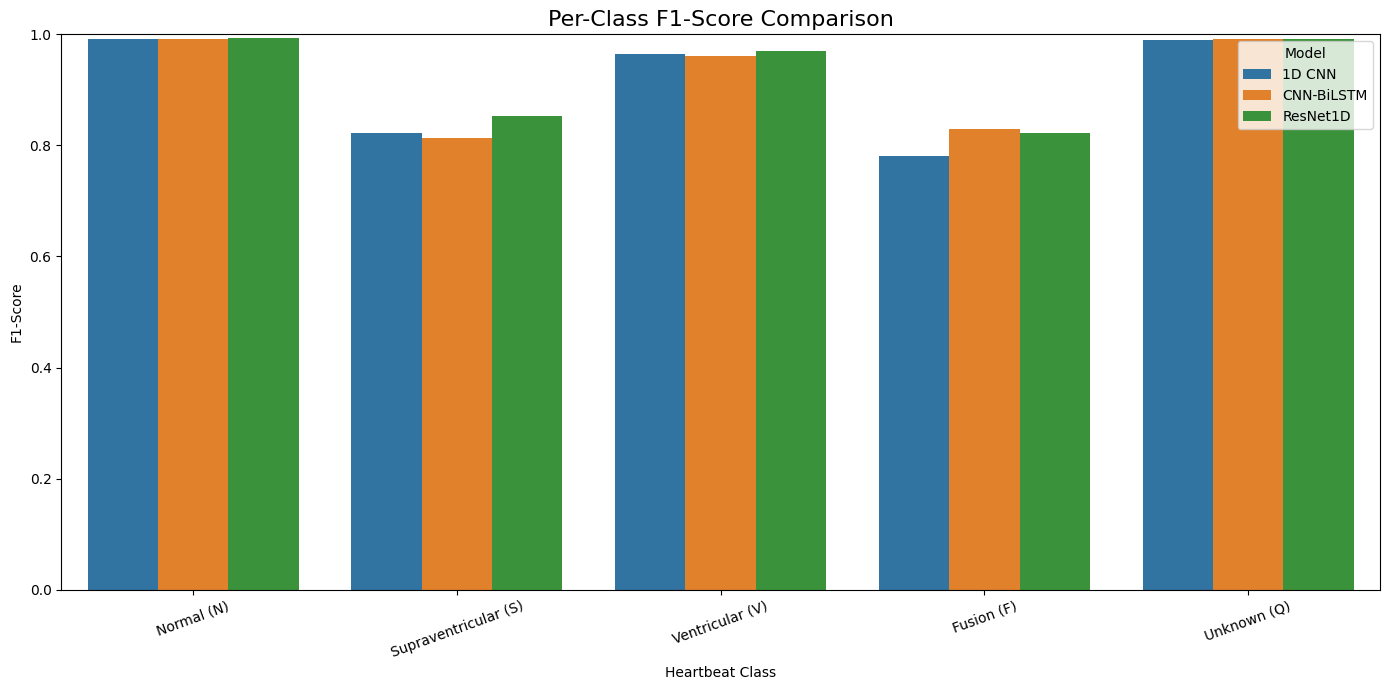

In [ ]:
plt.figure(figsize=(14, 7))
sns.barplot(data=per_class_results,x="Class",y="F1",hue="Model")
plt.title("Per-Class F1-Score Comparison",fontsize=16)
plt.xlabel("Heartbeat Class")
plt.ylabel("F1-Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.legend(title="Model")
plt.tight_layout()
plt.show()

**ROC-AUC**

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

y_test_one_hot = label_binarize(
    y_test,
    classes=np.arange(num_classes)
)

cnn_auc = roc_auc_score(
    y_test_one_hot,
    cnn_probabilities,
    multi_class="ovr",
    average="macro"
)

bilstm_auc = roc_auc_score(
    y_test_one_hot,
    bilstm_probabilities,
    multi_class="ovr",
    average="macro"
)

resnet_auc = roc_auc_score(
    y_test_one_hot,
    resnet_probabilities,
    multi_class="ovr",
    average="macro"
)

auc_results = pd.DataFrame({

    "Model": [
        "1D CNN",
        "CNN-BiLSTM",
        "ResNet1D"
    ],

    "Macro ROC-AUC": [
        cnn_auc,
        bilstm_auc,
        resnet_auc
    ]
})

display(
    auc_results.round(4)
)

,Model,Macro ROC-AUC
0,1D CNN,0.9950
1,CNN-BiLSTM,0.9933
2,ResNet1D,0.9946


# **Tuning Function**

In [ ]:
def residual_block(x, filters, kernel_size=5, dropout_rate=0.2):
    shortcut = x

    # First convolution
    x = layers.Conv1D(
        filters,
        kernel_size,
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(dropout_rate)(x)

    # Second convolution
    x = layers.Conv1D(
        filters,
        kernel_size,
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)

    # Match dimensions
    if shortcut.shape[-1] != filters:
        shortcut = layers.Conv1D(
            filters,
            1,
            padding="same",
            use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    # Residual connection
    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    return x

In [ ]:
def tunable_residual_block(x,filters,kernel_size=5,stride=1,dropout=0.20):
    shortcut = x
    # First convolution
    x = layers.Conv1D(filters=filters,kernel_size=kernel_size,strides=stride,padding="same",use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(dropout)(x)

    # Second convolution
    x = layers.Conv1D(filters=filters,kernel_size=kernel_size,padding="same",use_bias=False)(x)
    x = layers.BatchNormalization()(x)

    # Projection shortcut when dimensions change
    if shortcut.shape[-1] != filters or stride != 1:
        shortcut = layers.Conv1D(filters=filters,kernel_size=1,strides=stride,padding="same",use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    # Residual connection
    x = layers.Add()([x, shortcut])
    x = layers.Activation("relu")(x)

    return x

In [ ]:
def build_tunable_resnet1d(base_filters=64,dropout=0.20,learning_rate=0.001):

    inputs = layers.Input(shape=(187, 1))

    # INITIAL FEATURE EXTRACTION
    x = layers.Conv1D(filters=base_filters,kernel_size=7,padding="same",use_bias=False)(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(pool_size=2)(x)

    # RESIDUAL STAGE 1
    x = tunable_residual_block(x,filters=base_filters,kernel_size=5,dropout=dropout)
    x = tunable_residual_block(x,filters=base_filters,kernel_size=5,dropout=dropout)

    # RESIDUAL STAGE 2
    x = tunable_residual_block(x,filters=base_filters * 2,kernel_size=5,stride=2,dropout=dropout)
    x = tunable_residual_block(x,filters=base_filters * 2,kernel_size=5,dropout=dropout)

    # RESIDUAL STAGE 3
    x = tunable_residual_block(x,filters=base_filters * 4,kernel_size=3,stride=2,dropout=dropout)
    x = tunable_residual_block(x,filters=base_filters * 4,kernel_size=3,dropout=dropout)

    # CLASSIFIER
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128,activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(len(class_names),activation="softmax")(x)

    model = models.Model(inputs=inputs,outputs=outputs)
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer,loss="sparse_categorical_crossentropy",metrics=["accuracy"])

    return model

**Run Hyperparameter Tuning**

In [ ]:
tuning_configs = [
    {"base_filters": 32,"dropout": 0.20,"learning_rate": 0.001},
    {"base_filters": 64,"dropout": 0.20,"learning_rate": 0.001},
    {"base_filters": 64,"dropout": 0.30,"learning_rate": 0.001},
    {"base_filters": 64,"dropout": 0.30,"learning_rate": 0.0005},
    {"base_filters": 64,"dropout": 0.40,"learning_rate": 0.0005},
    {"base_filters": 128,"dropout": 0.30,"learning_rate": 0.0005}
]

print("Number of ResNet1D configurations:", len(tuning_configs))

Number of ResNet1D configurations: 6


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
tuning_results = []

for i, config in enumerate(tuning_configs,start=1):
    print("\n" + "=" * 70)
    print(f"RESNET1D CONFIGURATION {i}/{len(tuning_configs)}")
    print("=" * 70)
    print(f"Base Filters   : {config['base_filters']}")
    print(f"Dropout        : {config['dropout']}")
    print(f"Learning Rate  : {config['learning_rate']}")

    # Clear previous model
    tf.keras.backend.clear_session()

    # Build ResNet1D
    tuning_model = build_tunable_resnet1d(base_filters=config["base_filters"],dropout=config["dropout"],learning_rate=config["learning_rate"])

    # Callbacks
    tuning_early_stopping = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True,verbose=0)
    tuning_reduce_lr = ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=2,min_lr=1e-6,verbose=0)

    # Train
    tuning_history = tuning_model.fit(train_ds,validation_data=val_ds,epochs=15,class_weight=class_weights,
                                        callbacks=[tuning_early_stopping,tuning_reduce_lr],verbose=1)


    # VALIDATION PREDICTIONS
    val_prob = tuning_model.predict(X_val,verbose=0)
    val_pred = np.argmax(val_prob,axis=1)

    # VALIDATION METRICS
    val_accuracy = accuracy_score(y_val,val_pred)
    val_precision = precision_score(y_val,val_pred,average="macro",zero_division=0)
    val_recall = recall_score(y_val,val_pred,average="macro",zero_division=0)
    val_f1 = f1_score(y_val,val_pred,average="macro",zero_division=0)
    val_auc = roc_auc_score(y_val,val_prob,multi_class="ovr",average="macro")

    # STORE RESULTS
    tuning_results.append({
        "Configuration": i,
        "Base Filters":config["base_filters"],
        "Dropout":config["dropout"],
        "Learning Rate":config["learning_rate"],
        "Validation Accuracy":val_accuracy,
        "Macro Precision":val_precision,
        "Macro Recall":val_recall,
        "Macro F1":val_f1,
        "Macro ROC-AUC":val_auc,
        "Epochs":len(tuning_history.history["loss"])
    })

    print("\nValidation Results")
    print("-" * 50)
    print(f"Accuracy       : {val_accuracy:.4f}")
    print(f"Macro Precision: {val_precision:.4f}")
    print(f"Macro Recall   : {val_recall:.4f}")
    print(f"Macro F1       : {val_f1:.4f}")
    print(f"Macro ROC-AUC  : {val_auc:.4f}")

    # Free memory
    del tuning_model
    del tuning_history
    gc.collect()
    tf.keras.backend.clear_session()


RESNET1D CONFIGURATION 1/6
Base Filters   : 32
Dropout        : 0.2
Learning Rate  : 0.001
Epoch 1/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 36s 63ms/step - accuracy: 0.8375 - loss: 0.4815 - val_accuracy: 0.0254 - val_loss: 3.7232 - learning_rate: 0.0010
Epoch 2/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9444 - loss: 0.2292 - val_accuracy: 0.2970 - val_loss: 2.2118 - learning_rate: 0.0010
Epoch 3/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9526 - loss: 0.1821 - val_accuracy: 0.9724 - val_loss: 0.0914 - learning_rate: 0.0010
Epoch 4/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9600 - loss: 0.1545 - val_accuracy: 0.9533 - val_loss: 0.1505 - learning_rate: 0.0010
Epoch 5/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9611 - loss: 0.1433 - val_accuracy: 0.9673 - val_loss: 0.1127 - learning_rate: 0.0010
Epoch 6/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9699 - loss: 0.1160 - val_accuracy: 0.9749 - val_loss: 0.1025 - learning_ra

**Find Best Hyperparameters**

In [ ]:
tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df = tuning_results_df.sort_values(by="Macro F1",ascending=False).reset_index(drop=True)
display(tuning_results_df.round(4))

,Configuration,Base Filters,Dropout,Learning Rate,Validation Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC,Epochs
0,6,128,0.3,0.0005,0.9842,0.9074,0.9171,0.9087,0.9959,13
1,4,64,0.3,0.0005,0.9797,0.8572,0.9303,0.8863,0.9950,14
2,1,32,0.2,0.0010,0.9724,0.8878,0.8646,0.8744,0.9903,6
3,2,64,0.2,0.0010,0.9721,0.9208,0.8457,0.8740,0.9912,7
4,3,64,0.3,0.0010,0.9682,0.8585,0.8526,0.8526,0.9878,6
5,5,64,0.4,0.0005,0.9592,0.7813,0.8992,0.8091,0.9891,9


In [ ]:
best_config = tuning_results_df.iloc[0]

print("=" * 70)
print("BEST TUNED RESNET1D CONFIGURATION")
print("=" * 70)
print(f"Base Filters   : {int(best_config['Base Filters'])}")
print(f"Dropout        : {best_config['Dropout']}")
print(f"Learning Rate  : {best_config['Learning Rate']}")
print("\nValidation Performance")
print("-" * 50)
print(f"Accuracy       : {best_config['Validation Accuracy']:.4f}")
print(f"Macro Precision: {best_config['Macro Precision']:.4f}")
print(f"Macro Recall   : {best_config['Macro Recall']:.4f}")
print(f"Macro F1       : {best_config['Macro F1']:.4f}")
print(f"Macro ROC-AUC  : {best_config['Macro ROC-AUC']:.4f}")

BEST TUNED RESNET1D CONFIGURATION
Base Filters   : 128
Dropout        : 0.3
Learning Rate  : 0.0005

Validation Performance
--------------------------------------------------
Accuracy       : 0.9842
Macro Precision: 0.9074
Macro Recall   : 0.9171
Macro F1       : 0.9087
Macro ROC-AUC  : 0.9959


**Build Final Tuned 1D ResNet**

In [ ]:
best_base_filters = int(best_config["Base Filters"])
best_dropout = float(best_config["Dropout"])
best_learning_rate = float(best_config["Learning Rate"])
tf.keras.backend.clear_session()
final_tuned_resnet1d = build_tunable_resnet1d(
    base_filters=best_base_filters,
    dropout=best_dropout,
    learning_rate=best_learning_rate)

final_tuned_resnet1d.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 187, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 187, 128)  │        896 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 187, 128)  │        512 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 187, 128)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 93, 128)   │          0 │ activation[0][0]  │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 93, 128)   │     81,920 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 128)   │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 93, 128)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 93, 128)   │          0 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 93, 128)   │     81,920 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 128)   │        512 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 93, 128)   │          0 │ batch_normalizat… │
│                     │                   │            │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 93, 128)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 93, 128)   │     81,920 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 128)   │        512 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 93, 128)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 93, 128)   │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 93, 128)   │     81,920 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 128)   │        512 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 4,476,549 (17.08 MB)

 Trainable params: 4,467,333 (17.04 MB)

 Non-trainable params: 9,216 (36.00 KB)

**Train Final Tuned 1D ResNet**

In [ ]:
final_resnet_callbacks = [EarlyStopping(monitor="val_loss",patience=6,restore_best_weights=True,verbose=1),
                            ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,min_lr=1e-6,verbose=1)]

final_resnet_history = final_tuned_resnet1d.fit(train_ds,validation_data=val_ds,epochs=30,class_weight=class_weights,
                                                  callbacks=final_resnet_callbacks,verbose=1)

Epoch 1/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 59s 145ms/step - accuracy: 0.8245 - loss: 0.4976 - val_accuracy: 0.0254 - val_loss: 11.8404 - learning_rate: 5.0000e-04
Epoch 2/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 27s 97ms/step - accuracy: 0.9452 - loss: 0.2319 - val_accuracy: 0.0849 - val_loss: 4.8462 - learning_rate: 5.0000e-04
Epoch 3/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 27s 98ms/step - accuracy: 0.9547 - loss: 0.1892 - val_accuracy: 0.9358 - val_loss: 0.2122 - learning_rate: 5.0000e-04
Epoch 4/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 27s 99ms/step - accuracy: 0.9611 - loss: 0.1586 - val_accuracy: 0.9697 - val_loss: 0.1091 - learning_rate: 5.0000e-04
Epoch 5/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 28s 103ms/step - accuracy: 0.9642 - loss: 0.1431 - val_accuracy: 0.9502 - val_loss: 0.1852 - learning_rate: 5.0000e-04
Epoch 6/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 27s 99ms/step - accuracy: 0.9670 - loss: 0.1278 - val_accuracy: 0.9525 - val_loss: 0.1403 - learning_rate: 5.0000e-04
Epoch 7/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/s

**Final Tuned 1d ResNet Curves**

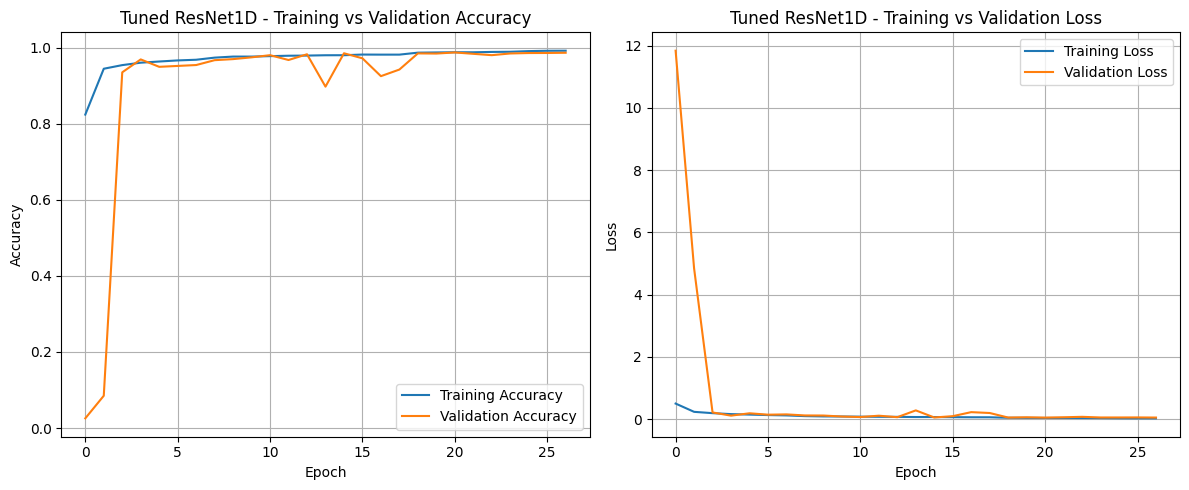

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(final_resnet_history.history["accuracy"],label="Training Accuracy")
plt.plot(final_resnet_history.history["val_accuracy"],label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Tuned ResNet1D - Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(final_resnet_history.history["loss"],label="Training Loss")

plt.plot(final_resnet_history.history["val_loss"],label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Tuned ResNet1D - Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Final Tuned 1D ResNet Predictions**

In [ ]:
test_prob = final_tuned_resnet1d.predict(X_test.squeeze(-1) if X_test.ndim == 4 else X_test,verbose=1)
test_pred = np.argmax(test_prob,axis=1)

685/685 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step


In [ ]:
tuned_resnet_test_prob = final_tuned_resnet1d.predict(X_test.squeeze(-1),verbose=1)
tuned_resnet_test_pred = np.argmax(tuned_resnet_test_prob,axis=1)

685/685 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step


**Final Tuned 1D ResNet Report**

In [ ]:
tuned_resnet_accuracy = accuracy_score(y_test,tuned_resnet_test_pred)
tuned_resnet_precision = precision_score(y_test,tuned_resnet_test_pred,average="macro",zero_division=0)
tuned_resnet_recall = recall_score(y_test,tuned_resnet_test_pred,average="macro",zero_division=0)
tuned_resnet_f1 = f1_score(y_test,tuned_resnet_test_pred,average="macro",zero_division=0)
tuned_resnet_auc = roc_auc_score(y_test,tuned_resnet_test_prob,multi_class="ovr",average="macro")

print("=" * 70)
print("FINAL TUNED RESNET1D - TEST RESULTS")
print("=" * 70)
print(f"Accuracy        : {tuned_resnet_accuracy:.4f}")
print(f"Macro Precision : {tuned_resnet_precision:.4f}")
print(f"Macro Recall    : {tuned_resnet_recall:.4f}")
print(f"Macro F1        : {tuned_resnet_f1:.4f}")
print(f"Macro ROC-AUC   : {tuned_resnet_auc:.4f}")

FINAL TUNED RESNET1D - TEST RESULTS
Accuracy        : 0.9876
Macro Precision : 0.9246
Macro Recall    : 0.9311
Macro F1        : 0.9273
Macro ROC-AUC   : 0.9940


In [ ]:
print("=" * 70)
print("TUNED RESNET1D CLASSIFICATION REPORT")
print("=" * 70)
print(classification_report( y_test,tuned_resnet_test_pred,target_names=list(class_names.values()),
                              digits=4,zero_division=0))

TUNED RESNET1D CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          Normal (N)     0.9933    0.9948    0.9940     18118
Supraventricular (S)     0.8847    0.8417    0.8627       556
     Ventricular (V)     0.9735    0.9641    0.9688      1448
          Fusion (F)     0.7778    0.8642    0.8187       162
         Unknown (Q)     0.9938    0.9907    0.9922      1608

            accuracy                         0.9876     21892
           macro avg     0.9246    0.9311    0.9273     21892
        weighted avg     0.9877    0.9876    0.9876     21892



**Final Tuned 1D ResNet Confusion Matrix**

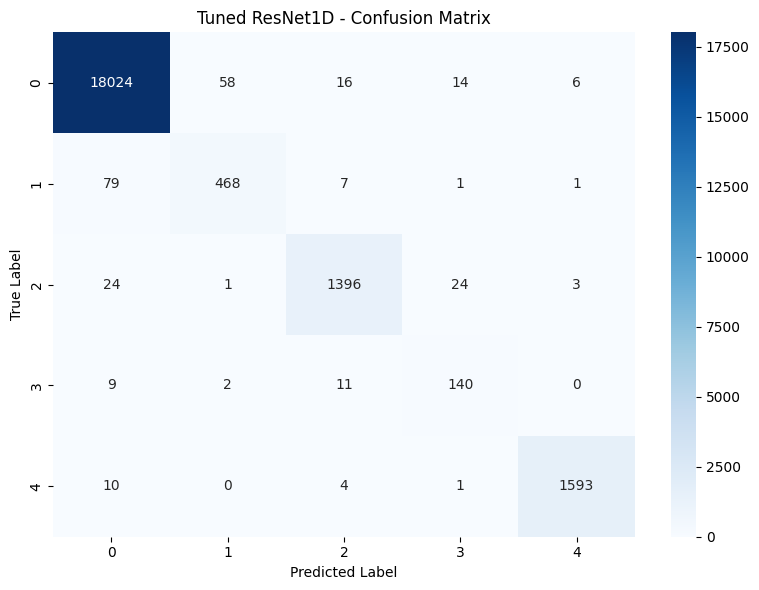

In [ ]:
cm_tuned_resnet = confusion_matrix(y_test,tuned_resnet_test_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_tuned_resnet,annot=True,fmt="d",cmap="Blues",xticklabels=class_names,yticklabels=class_names)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Tuned ResNet1D - Confusion Matrix")
plt.tight_layout()
plt.show()

**ORIGINAL VS TUNED RESNET1Dt**

In [ ]:
final_accuracy = tuned_resnet_accuracy
final_precision = tuned_resnet_precision
final_recall = tuned_resnet_recall
final_f1 = tuned_resnet_f1
final_auc = tuned_resnet_auc

resnet_tuning_comparison = pd.DataFrame({
    "Model": ["Original ResNet1D","Tuned ResNet1D"],
    "Accuracy": [results.loc[results['Model'] == 'ResNet1D', 'Accuracy'].iloc[0],final_accuracy],
    "Macro Precision": [results.loc[results['Model'] == 'ResNet1D', 'Macro Precision'].iloc[0],final_precision],
    "Macro Recall": [results.loc[results['Model'] == 'ResNet1D', 'Macro Recall'].iloc[0],final_recall],
    "Macro F1": [results.loc[results['Model'] == 'ResNet1D', 'Macro F1'].iloc[0],final_f1],
    "Macro ROC-AUC": [resnet_auc,final_auc]})
resnet_tuning_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,Original ResNet1D,0.987210,0.921117,0.933186,0.926239,0.994617
1,Tuned ResNet1D,0.987621,0.924601,0.931099,0.927283,0.994048


**IMPROVEMENT AFTER RESNET1D TUNING**

In [ ]:
improvement_df = pd.DataFrame({
    "Metric": ["Accuracy","Macro Precision","Macro Recall","Macro F1","Macro ROC-AUC"],
    "Original ResNet1D": [
        results.loc[results['Model'] == 'ResNet1D', 'Accuracy'].iloc[0],
        results.loc[results['Model'] == 'ResNet1D', 'Macro Precision'].iloc[0],
        results.loc[results['Model'] == 'ResNet1D', 'Macro Recall'].iloc[0],
        results.loc[results['Model'] == 'ResNet1D', 'Macro F1'].iloc[0],
        resnet_auc],
    "Tuned ResNet1D": [final_accuracy,final_precision,final_recall,final_f1,final_auc]})

improvement_df["Change (%)"] = (improvement_df["Tuned ResNet1D"]- improvement_df["Original ResNet1D"]) * 100

improvement_df

,Metric,Original ResNet1D,Tuned ResNet1D,Change (%)
0,Accuracy,0.987210,0.987621,0.041111
1,Macro Precision,0.921117,0.924601,0.348357
2,Macro Recall,0.933186,0.931099,-0.208712
3,Macro F1,0.926239,0.927283,0.104390
4,Macro ROC-AUC,0.994617,0.994048,-0.056901


**COMPLETE FOUR-MODEL COMPARISON**

In [ ]:
comparison_df = pd.DataFrame({

    "Model": ["1D CNN","CNN-BiLSTM","ResNet1D","Tuned ResNet1D"],
    "Accuracy": [
        results.loc[results['Model'] == '1D CNN', 'Accuracy'].iloc[0],
        results.loc[results['Model'] == 'CNN-BiLSTM', 'Accuracy'].iloc[0],
        results.loc[results['Model'] == 'ResNet1D', 'Accuracy'].iloc[0],
        final_accuracy],
    "Macro Precision": [
        results.loc[results['Model'] == '1D CNN', 'Macro Precision'].iloc[0],
        results.loc[results['Model'] == 'CNN-BiLSTM', 'Macro Precision'].iloc[0],
        results.loc[results['Model'] == 'ResNet1D', 'Macro Precision'].iloc[0],
        final_precision],
    "Macro Recall": [
        results.loc[results['Model'] == '1D CNN', 'Macro Recall'].iloc[0],
        results.loc[results['Model'] == 'CNN-BiLSTM', 'Macro Recall'].iloc[0],
        results.loc[results['Model'] == 'ResNet1D', 'Macro Recall'].iloc[0],
        final_recall],
    "Macro F1": [
        results.loc[results['Model'] == '1D CNN', 'Macro F1'].iloc[0],
        results.loc[results['Model'] == 'CNN-BiLSTM', 'Macro F1'].iloc[0],
        results.loc[results['Model'] == 'ResNet1D', 'Macro F1'].iloc[0],
        final_f1],
    "Macro ROC-AUC": [cnn_auc,bilstm_auc,resnet_auc,final_auc]})

comparison_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,1D CNN,0.982962,0.883644,0.942439,0.909893,0.994978
1,CNN-BiLSTM,0.984012,0.912859,0.921870,0.917201,0.993298
2,ResNet1D,0.987210,0.921117,0.933186,0.926239,0.994617
3,Tuned ResNet1D,0.987621,0.924601,0.931099,0.927283,0.994048


**RANK MODELS BY MACRO F1**

In [ ]:
comparison_ranked = comparison_df.sort_values(by="Macro F1",ascending=False).reset_index(drop=True)

print("MODEL RANKING BASED ON MACRO F1")
print("====================================")
print(comparison_ranked.round(4))


MODEL RANKING BASED ON MACRO F1
            Model  Accuracy  Macro Precision  Macro Recall  Macro F1  \
0  Tuned ResNet1D    0.9876           0.9246        0.9311    0.9273   
1        ResNet1D    0.9872           0.9211        0.9332    0.9262   
2      CNN-BiLSTM    0.9840           0.9129        0.9219    0.9172   
3          1D CNN    0.9830           0.8836        0.9424    0.9099   

   Macro ROC-AUC  
0         0.9940  
1         0.9946  
2         0.9933  
3         0.9950  


**Comparison of all four models**

In [ ]:

comparison_display = comparison_ranked.copy()
metric_columns = ["Accuracy","Macro Precision","Macro Recall","Macro F1","Macro ROC-AUC"]

for col in metric_columns:
    comparison_display[col] = (comparison_display[col] * 100).round(2)

comparison_display

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,Tuned ResNet1D,98.76,92.46,93.11,92.73,99.40
1,ResNet1D,98.72,92.11,93.32,92.62,99.46
2,CNN-BiLSTM,98.40,91.29,92.19,91.72,99.33
3,1D CNN,98.30,88.36,94.24,90.99,99.50


**ACCURACY COMPARISON**

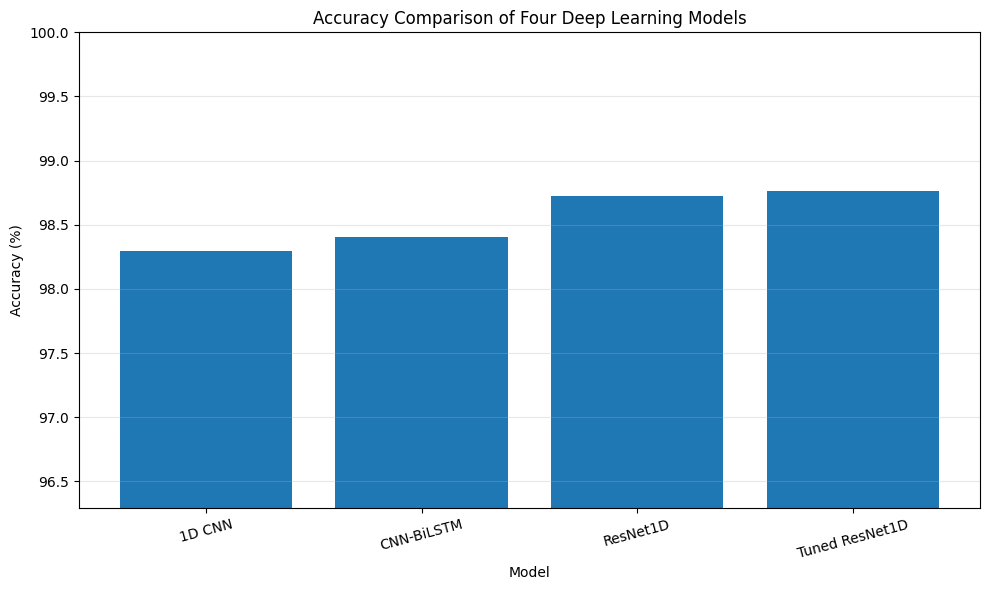

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(comparison_df["Model"],comparison_df["Accuracy"] * 100)
plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Accuracy Comparison of Four Deep Learning Models")
plt.ylim(max(90, (comparison_df["Accuracy"].min() * 100) - 2),100)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**MACRO F1 COMPARISON**

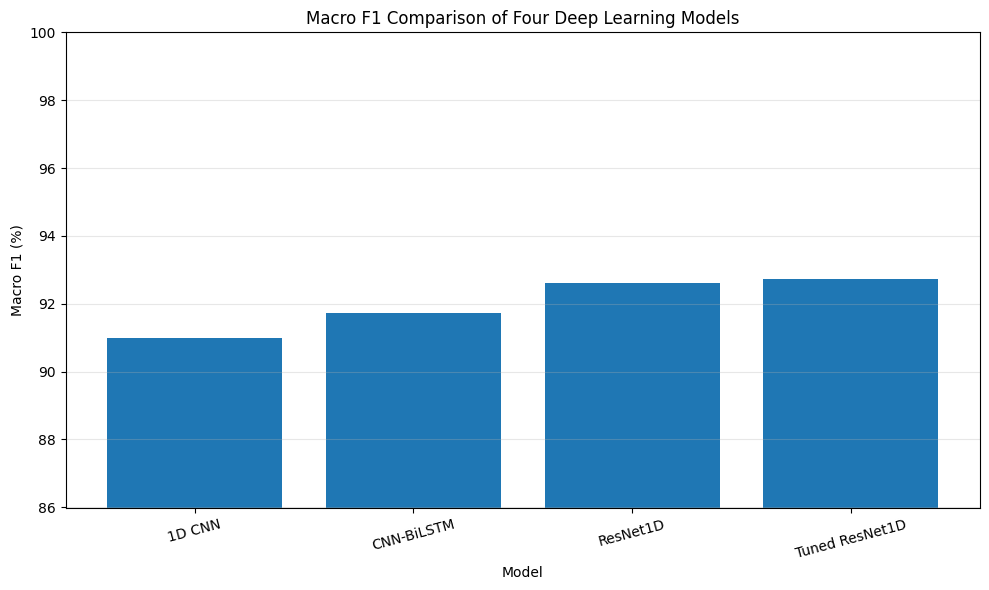

In [ ]:

plt.figure(figsize=(10, 6))
plt.bar(comparison_df["Model"],comparison_df["Macro F1"] * 100)
plt.ylabel("Macro F1 (%)")
plt.xlabel("Model")
plt.title("Macro F1 Comparison of Four Deep Learning Models")
plt.ylim(max(70, (comparison_df["Macro F1"].min() * 100) - 5),100)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**ALL METRICS COMPARISON**

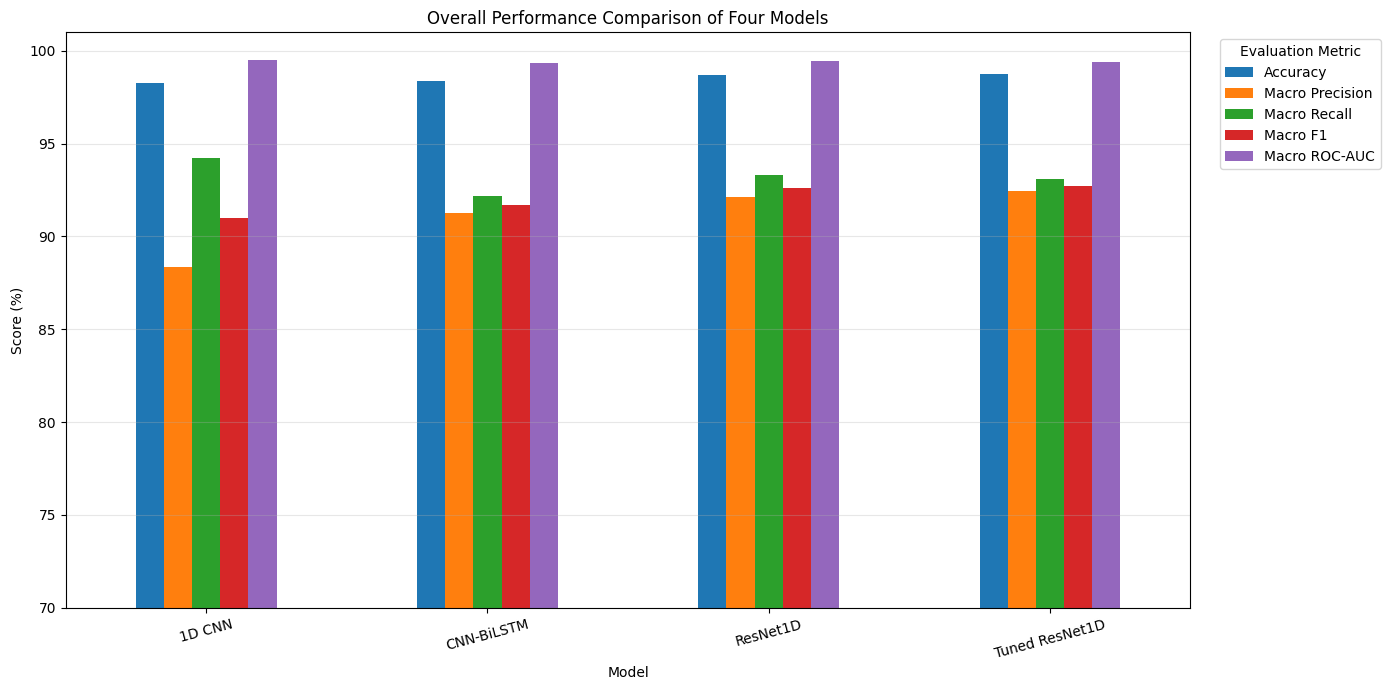

In [ ]:
metrics_to_plot = ["Accuracy","Macro Precision","Macro Recall","Macro F1","Macro ROC-AUC"]
comparison_plot_df = comparison_df.set_index("Model")[metrics_to_plot] * 100
comparison_plot_df.plot(kind="bar",figsize=(14, 7))
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.title("Overall Performance Comparison of Four Models")
plt.ylim(70, 101)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Evaluation Metric",bbox_to_anchor=(1.02, 1),loc="upper left")
plt.tight_layout()
plt.show()

**BEST MODEL**

In [ ]:
best_model = comparison_df.loc[comparison_df["Macro F1"].idxmax()]
print("=================")
print("BEST PERFORMING MODEL")
print("=================")
print(best_model.round(4))


BEST PERFORMING MODEL
Model              Tuned ResNet1D
Accuracy                 0.987621
Macro Precision          0.924601
Macro Recall             0.931099
Macro F1                 0.927283
Macro ROC-AUC            0.994048
Name: 3, dtype: object
